# [예시] 코드북으로 결과 내기: 5일차 민원 테마 · 6일차 리뷰 속성

5 · 6일차 실습의 실제 데이터로 코드북을 쓰고, 그 코드북으로 나눈 결과를 표와 결론 문장으로 정리합니다.

- **1부(5일차)**: 공정거래위원회 소비자 민원 2만 건. 토픽을 테마로 써도 되는지 확인(시드 안정성 · 이름 확인)하고, 코드북 항목을 써서 테마별 건수 · 비율 · 원인 표를 만듭니다.
- **2부(6일차)**: 네이버 쇼핑 리뷰와 그 리뷰의 LLM 라벨. 코드북이 프롬프트가 되는 과정, 라벨 확인, 속성별 부정 비율과 95% 구간, 전임 담당자의 틀린 집계를 다룹니다.

코드북 항목 없이 이름만으로 분류하면 같은 민원 2만 건에서 헬스장 해지 · 환불 테마로 분류되는 민원이 10배 넘게 늘어납니다(1-5). 리뷰에서는 경계 기준이 없으면 배송 불만 일부가 품질 불만으로 분류됩니다(2-5).

실행: 위에서부터 차례로 실행합니다. GPU 는 필요 없고, 처음 한 번은 자료를 받느라 1분 안팎 걸립니다. LLM 라벨은 LLM 을 호출하지 않고 과정 결과 파일에서 읽습니다.

### 준비: 패키지와 한글 폰트

새로 설치하는 패키지는 없습니다. Colab 이면 한글 폰트(나눔고딕)만 설치하고, 그림 크기 · 글자 크기를 맞춥니다.

In [ ]:
# 준비: 패키지 · 한글 폰트(폰트 설치는 Colab 에서만 합니다)
#  이 예시는 새로 설치할 패키지가 없습니다. 민원별 명사 목록 · 토픽 배정 · 이름 초안은 과정 결과를 읽으므로
#  kiwipiepy · bertopic · transformers 가 필요 없습니다. Colab 에서는 한글 폰트만 설치합니다.
import os, sys, math, time
import subprocess
IN_COLAB = "google.colab" in sys.modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import warnings; warnings.filterwarnings("ignore")

# 한글 폰트: Colab 이면 나눔고딕을 설치한 뒤 그 ttf 를 폰트 목록에 **직접** 등록한다.
#  설치는 디스크에 파일만 만든다. 이미 떠 있는 폰트 목록은 그 사실을 모르므로 addfont 로
#  등록해야 이름이 보인다(등록하지 않으면 DejaVu Sans 로 밀려 한글이 전부 □ 로 나온다).
import glob, shutil
if IN_COLAB and shutil.which("apt-get"):
    subprocess.run(["apt-get", "-y", "-qq", "install", "fonts-nanum"], check=False)
for _p in glob.glob("/usr/share/fonts/truetype/nanum/Nanum*.ttf"):   # 설치 여부와 무관하게 한 번
    try: fm.fontManager.addfont(_p)
    except Exception: pass
try: fm._get_font.cache_clear()
except Exception: pass
installed = {f.name for f in fm.fontManager.ttflist}
FONT = next((n for n in ["Pretendard", "Apple SD Gothic Neo", "NanumGothic"] if n in installed), "DejaVu Sans")
plt.rcParams["font.family"] = FONT
plt.rcParams["axes.unicode_minus"] = FONT in {"Pretendard", "DejaVu Sans"}   # 나머지 폰트에는 U+2212 가 없다
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}   # 그림마다 폭이 깎이지 않게
plt.rcParams["figure.dpi"] = plt.rcParams["savefig.dpi"] = 150       # 폭 FIG_W x 150dpi = 1500px 고정
plt.rcParams["figure.autolayout"] = True
plt.rcParams.update({"font.size": 11, "axes.titlesize": 15, "axes.labelsize": 12,
                     "legend.fontsize": 11, "figure.titlesize": 17, "font.weight": "regular",
                     "text.color": "black", "axes.labelcolor": "black", "axes.titlecolor": "black",
                     "axes.edgecolor": "#757575", "xtick.color": "#757575", "ytick.color": "#757575",
                     "xtick.labelcolor": "black", "ytick.labelcolor": "black",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False})

# 이 실습의 그림 전체가 함께 쓰는 색: 기준선=남색, 관측=파랑, 강조=하늘색, 문맥=회색
COL = {"남색": "#051C2C", "파랑": "#2251FF", "하늘색": "#00A9F4",
       "회색": "#757575", "연회색": "#B3B3B3"}
FIG_W = 10.0     # 캔버스 폭은 이 실습의 그림 모두 이 값으로 고정하고 높이만 그림마다 조절한다

from importlib.metadata import version as _ver, PackageNotFoundError
_need = ["pandas", "pyarrow", "scikit-learn"]
_have = {}
for _name in _need:
    try:
        _have[_name] = _ver(_name)
    except PackageNotFoundError:
        _have[_name] = "없음"
print("사용 폰트:", FONT, "| 색 팔레트 준비 완료 |", " · ".join(f"{k} {v}" for k, v in _have.items()))
_miss = [k for k in _need if _have[k] == "없음"]
if _miss:
    print("참고: 설치되지 않은 패키지가 있습니다(" + " · ".join(_miss) + "). Colab 에는 모두 들어 있고,"
          " 내 컴퓨터라면 pip 로 설치합니다.")

사용 폰트: NanumGothic | 색 팔레트 준비 완료 | pandas 2.2.3 · pyarrow 23.0.1 · scikit-learn 1.6.1


## 1부 5일차: 민원 토픽으로 테마 코드북 쓰기

자료와 자료 준비 코드는 5일차 실습에서 가져왔습니다.

| 자료 | 쓰는 것 |
|---|---|
| 공정거래위원회 소비자 민원 2020(data.go.kr 15098314) | 무작위 2만 건의 민원 제목 · 품목명 · 연령대 |
| 토픽 배정(과정 결과) | 시드 0 · 1 · 2 로 적합한 BERTopic 토픽 번호, 시드 0 소속 확률 |
| 민원별 명사 목록(과정 결과) | 토픽 상위 단어와 대표 문서 점수를 계산하는 입력 |
| 코드북 v0(과정 결과) | 토픽 0～7 의 LLM 이름 초안과 이름 확인 표본 10건 |

**자료 준비 ① 주소**: 패키지를 불러오고, 원자료(공정거래위원회 민원 CSV)와 과정 결과 파일을 받을 주소를 정합니다.

In [ ]:
# 자료 준비 ① 주소: 민원 원자료 · 토픽 배정 · 민원별 명사 목록 · 코드북 v0 을 받을 주소
# BERTopic 적합과 LLM 호출은 하지 않고 과정 결과 파일을 읽습니다
import os, re, time, hashlib, urllib.request
from decimal import Decimal, ROUND_HALF_UP
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# 원자료: 원 출처 URL · 파일 이름 · SHA-256(2026-09-24 확인) · 데이터 페이지
RAW_FILES = {
    "complaints": ("https://www.data.go.kr/cmm/cmm/fileDownload.do?"
                   "atchFileId=FILE_000000002610054&fileDetailSn=1&insertDataPrcus=N",
                   "kftc_complaints_1.csv",
                   "50c098fea2ec1d05191d07c45cd0f75b4d0ac3b5e5ac36910fe40f2aab699ebe",
                   "https://www.data.go.kr/data/15098314/fileData.do"),
}
DATA_URL = "https://github.com/studio-js/korean-cx-text/raw/main/data"   # 과정 결과(민원별 명사 목록 · 토픽 배정)를 받는 주소
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"  # 과정 복제본: 원 출처와 같은 바이트, 먼저 받는 곳

**자료 준비 ② 파일 찾기 · 받기 함수**: `nlp_data` 폴더에서 파일을 찾는 함수와 파일의 SHA-256 을 계산하는 함수를 정의합니다. 받기에 실패하면 3번까지 다시 받습니다.

In [ ]:
# 자료 준비 ② 파일 찾기 · 받기 함수
def data_dir():
    # 자료 폴더: 환경변수 NLP_DATA_DIR 이 있으면 그 폴더, 없으면 ./nlp_data
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    # 자료 폴더 → cache/ → raw/ → processed/ 순서로 찾아 처음 나온 경로, 없으면 None
    for sub in ("", "cache", "raw", "processed"):
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _download(url, path, retries=3):
    # url 을 path 로 받는다: 실패하면 세 번까지 다시 시도
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    for i in range(retries):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            os.replace(path + ".part", path)
            return True
        except Exception as e:
            print(f"받기 실패 {i + 1}/{retries}: {e}")
            time.sleep(2 * (i + 1))
    return False

**자료 준비 ③ 원자료 · 과정 결과 받기 함수**: 원자료는 받은 뒤 SHA-256 으로 원본과 같은지 확인합니다. 과정 결과(토픽 배정 등)는 과정 저장소에서 받습니다. `rnd` 는 반올림 함수입니다.

In [ ]:
# 자료 준비 ③ 원자료 · 과정 결과 받기 함수
def fetch_raw(name):
    # 원자료 경로: 로컬을 먼저 보고, 없으면 과정 복제본(MIRROR_URL) → 원 출처 URL 순서로 받아 자료 폴더/cache/ 에 둔다
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = os.path.join(data_dir(), "cache", fname)
        if _download(f"{MIRROR_URL}/{fname}", path) and sha256_of(path) != sha:  # 복제본이 다르면 버리고 원 출처로
            os.remove(path)
        if not os.path.isfile(path) and not _download(url, path):
            raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 본문의 수와 다를 수 있습니다(데이터 페이지: {page})")
    return path


def fetch_precomputed(name):
    # 과정 결과 경로: 내 폴더에 있으면 그 파일, 없으면 DATA_URL/name 에서 받는다. 받지 못하면 멈춘다
    path = find_local(name)
    if path is None and DATA_URL.startswith("http"):
        path = os.path.join(data_dir(), "cache", name)
        if not _download(f"{DATA_URL}/{name}", path):
            path = None
    if path is None:
        raise RuntimeError(f"과정 결과 {name} 을 받지 못했습니다: DATA_URL 이 비어 있거나 내려받기가"
                           " 실패했습니다. 강사에게 파일 위치를 물어 주세요")
    return path


def rnd(x, digits):
    # 십진 값 기준 반올림(끝자리 5 는 올림): 교안의 수와 같은 계산
    return float(Decimal(f"{float(x):.12g}").quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))

**자료 준비 ④ 민원 원자료 읽기 함수**: 시험 입력과 빈 제목을 빼고 전화번호를 [전화번호] 로 바꾸는 함수를 정의합니다. 무작위로 행을 고르는 함수도 정의합니다.

In [ ]:
# 자료 준비 ④ 민원 원자료 읽기: 5일차 전처리처럼 시험 입력과 빈 제목을 빼고 전화번호를 [전화번호] 로 바꿉니다
TEST_INPUT_RE = re.compile(
    r"(?i)^\s*(?:test|테스트)\s*(?:입니다)?\s*\.?\s*$"
    r"|IN-TEST"
    r"|(?:인바운드|아웃바운드|녹취|수화기).*테스트|테스트.*(?:인바운드|아웃바운드|녹취|수화기)"
    r"|^\s*자동차\s*(?:상담\s*)?테스트"
    r"|^\s*\d{8}\s*[-_ ].*테스트"
    r"|테스트\s*데이터|상담\s*(?:전화\s*)?테스트|전화\s*테스트|헬프데스크\s*시험|^\s*일반\s*테스트")
EMPTY_TITLE_RE = re.compile(r"^[^가-힣A-Za-z]*$")   # 한글 음절도 로마자도 없는 민원 제목(「-」「.」「0」「ㅇ」)
PHONE_RE = re.compile(r"(?<!\d)(?:01[016789]|0\d{1,2})[-.)\s]{0,2}\d{3,4}[-.\s]\d{4}(?!\d)")


def read_complaints(path, verbose=True):
    # 민원 파일(cp949) 읽기 → 열 이름에서 괄호 안 영문을 떼고, 시험 입력·빈 민원 제목 행을 빼고, 전화번호 형태를 가린다
    raw = pd.read_csv(path, encoding="cp949", dtype=str)
    df = raw.rename(columns=lambda c: c.split("(")[0].strip())
    df.insert(0, "row_id", range(len(df)))          # 원자료의 행 번호(0부터)
    title = df["사건제목"].fillna("").str.strip()
    is_test = title.str.contains(TEST_INPUT_RE)
    is_empty = title.str.match(EMPTY_TITLE_RE) & ~is_test
    df = df[~is_test & ~is_empty].copy()
    title = title[df.index]
    df["사건제목"] = title.map(lambda t: PHONE_RE.sub("[전화번호]", t))
    df = df.reset_index(drop=True)
    if verbose:
        print(f"민원 원본 {len(raw):,}행 → 시험 입력 {int(is_test.sum())}행·빈 민원 제목 {int(is_empty.sum())}행 제거"
              f" → {len(df):,}행")
    return df


def sample_rows(df, n, seed=0):
    # 고정 표본: 같은 입력과 같은 seed 면 같은 행이 같은 순서로 나온다
    return df.sample(n=n, random_state=seed)

**자료 준비 ⑤ 토픽 배정 합치기**: 민원 2만 건을 읽고, 과정이 BERTopic 을 미리 적합해 얻은 토픽 번호(시드 0 · 1 · 2)를 행 번호로 합칩니다. `t0` 은 시드 0 의 토픽 번호이고 −1 은 이상치입니다.

In [ ]:
# 토픽 배정(과정 결과): 행 번호 · 시드 0·1·2 의 토픽 번호 · 시드 0 소속 확률. 민원 표본과 행 번호로 합칩니다
import json
_assign = pd.read_parquet(fetch_precomputed("topics_complaints.parquet"),
                          columns=["row_id", "rank", "topic_s0", "topic_s1", "topic_s2", "prob_s0", "ver"])
_assign = _assign.sort_values("rank").reset_index(drop=True)
TOPICS_VER = str(_assign["ver"].iloc[0])
_cols = ["row_id", "사건제목", "품목명", "연령대명"]
_sample = sample_rows(read_complaints(fetch_raw("complaints"), verbose=False), 20000, seed=0)[_cols]
SAMPLE = _assign[["row_id", "topic_s0", "topic_s1", "topic_s2", "prob_s0"]].merge(_sample, on="row_id", how="left")
SAMPLE[["topic_s0", "topic_s1", "topic_s2"]] = SAMPLE[["topic_s0", "topic_s1", "topic_s2"]].astype(int)
SAMPLE["prob_s0"] = SAMPLE["prob_s0"].astype(float)
t0 = SAMPLE["topic_s0"].to_numpy()                    # 시드 0 의 토픽 번호(−1 은 이상치)
n_topics = int(t0.max()) + 1

**자료 준비 ⑥ 토픽 상위 단어와 대표 문서 점수**: 민원별 명사로 토픽마다 상위 단어(c-TF-IDF)를 구합니다. 민원마다 자기 토픽의 상위 단어와 얼마나 닮았는지(`DOC_SIM`)도 계산합니다. `DOC_SIM` 이 클수록 그 토픽을 잘 대표하는 민원입니다.

In [ ]:
# 상위 단어와 대표 문서 점수: 민원별 명사 목록으로 토픽마다 c-TF-IDF 를 계산합니다(BERTopic 의 c-TF-IDF 식)
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import normalize
_nouns = pd.read_parquet(fetch_precomputed("complaints_nouns.parquet"))
_tokdoc = SAMPLE[["row_id"]].merge(_nouns, on="row_id", how="left")["명사"].map(lambda ws: " ".join(ws)).tolist()
STOP_COMPLAINTS = ["문의", "요청", "관련", "요구", "건", "후", "상담", "불만", "피해"]   # 민원 불용어 9개
_joined = pd.DataFrame({"d": _tokdoc, "t": t0}).groupby("t")["d"].apply(" ".join)
_cv = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, min_df=2, stop_words=STOP_COMPLAINTS)
_Xc = _cv.fit_transform(_joined.tolist()).astype(float)
_A = int(np.asarray(_Xc.sum(axis=1)).mean())
_idf = np.log(1 + _A / np.asarray(_Xc.sum(axis=0)).ravel())
_W = normalize(_Xc, norm="l1").multiply(_idf).tocsr()
_vocab = np.array(_cv.get_feature_names_out())
TOPIC_WORDS = {int(k): [str(w) for w in _vocab[np.argsort(-_W[i].toarray().ravel())[:5]]]
               for i, k in enumerate(_joined.index)}          # {토픽 번호: 상위 단어 5개}
_row = {k: i for i, k in enumerate(_joined.index)}
_D = normalize(normalize(_cv.transform(_tokdoc).astype(float), norm="l1").multiply(_idf).tocsr())
DOC_SIM = np.asarray(_D.multiply(normalize(_W)[[_row[k] for k in t0]]).sum(axis=1)).ravel()

**자료 준비 ⑦ 코드북 v0 읽기**: 토픽 0～7 의 LLM 이름 초안 · 테마 이름 · 이름 확인 표본을 읽습니다(`CB_ROWS`). 출력 끝의 표는 LLM 이름 초안이 첫 확인 10건 가운데 몇 건에 맞았는지 보여 줍니다.

In [ ]:
# 코드북 v0(과정 결과): 토픽 0～7 의 이름 초안 · 테마 이름 · 이름 확인 표본과 AI 판단
CODEBOOK = json.load(open(fetch_precomputed("course_codebook_v0.json"), encoding="utf-8"))
CB_ROWS = {int(r["토픽"]): r for r in CODEBOOK["rows"]}
THEMES = list(range(8))

print(f"준비 끝: 민원 {len(SAMPLE):,}건 · 시드 0 토픽 {n_topics}개 · 이상치(−1) {rnd(100 * (t0 == -1).mean(), 2)}%")
print(f"토픽 배정 버전 {TOPICS_VER} · 시드만 0 · 1 · 2 로 바꾼 세 번의 적합")
print(f"토픽 0～7 의 민원 {int(np.isin(t0, THEMES).sum()):,}건 · 토픽 36 의 민원 {int((t0 == 36).sum())}건")
print(f"코드북 v0 항목 {len(CB_ROWS)}개 · 이름 확인의 맞음 · 아님은 AI 판단(사람의 정답이 아님)")
print()
print("표 2 · 토픽 0～7 의 LLM 이름 초안과 첫 확인에서 맞은 건수")
name_table = pd.DataFrame({"토픽": THEMES, "이름 초안": [CB_ROWS[k]["LLM 이름 초안"] for k in THEMES],
                           "맞은 건수(10건 가운데)": [CB_ROWS[k]["검산"][0]["맞음"] for k in THEMES]})
print(name_table.to_string(index=False))

준비 끝: 민원 20,000건 · 시드 0 토픽 40개 · 이상치(−1) 33.05%
토픽 배정 버전 topics-v1-20260924 · 시드만 0 · 1 · 2 로 바꾼 세 번의 적합
토픽 0～7 의 민원 6,409건 · 토픽 36 의 민원 109건
코드북 v0 항목 8개 · 이름 확인의 맞음 · 아님은 AI 판단(사람의 정답이 아님)

표 2 · 토픽 0～7 의 LLM 이름 초안과 첫 확인에서 맞은 건수
 토픽     이름 초안  맞은 건수(10건 가운데)
  0 휴대폰 개통 철회               0
  1   국외여행 취소               2
  2 중고차 보증 수리               0
  3  해지 환불 민원              10
  4 정수기 렌탈 민원               9
  5  세탁 관련 민원               4
  6 코로나 예식 취소               2
  7   주식자문 계약               9


### 1-1 원문 읽기: 토픽 3 의 민원

코드북의 기준은 원문에서 나옵니다. 토픽 3 의 상위 단어 · 품목명 · 대표 민원을 보고, 이름에 맞는지 판단이 갈리는 경계 사례를 찾습니다.

판단에 쓸 단어 목록부터 정합니다. 코드북 v1 의 「시설」 기준(운동 시설 · 강습)과 「사건」 기준(해지 · 환불)을 단어로 옮긴 것이고, 1-5 의 분류에도 씁니다.

In [ ]:
# 1-1 ① 코드북 v1 의 판단 기준을 단어 목록으로: 시설(운동 시설 · 강습)과 사건(해지 · 환불)
import re
GYM_ITEMS = ["헬스장", "종합체육시설회원권", "스포츠시설이용", "수영장회원권"]          # 운동 시설 품목명
SPORT_RE = r"헬스|휘트니스|피트니스|필라테스|요가|폴댄스|PT|피티|수영|크로스핏|복싱|골프|발레|댄스|스피닝|체육관|운동(?!화)"
GOODS = ["운동화", "스포츠웨어"]                                                  # 운동 「물건」은 시설이 아님
EVENT_RE = r"해지|환불|환급|위약|취소|해제|철회|중도|반환"                              # 해지 · 환불 사건
print("시설 품목:", " · ".join(GYM_ITEMS))
print("시설 단어:", SPORT_RE.replace("|", " · "))
print("사건 단어:", EVENT_RE.replace("|", " · "))

시설 품목: 헬스장 · 종합체육시설회원권 · 스포츠시설이용 · 수영장회원권
시설 단어: 헬스 · 휘트니스 · 피트니스 · 필라테스 · 요가 · 폴댄스 · PT · 피티 · 수영 · 크로스핏 · 복싱 · 골프 · 발레 · 댄스 · 스피닝 · 체육관 · 운동(?!화)
사건 단어: 해지 · 환불 · 환급 · 위약 · 취소 · 해제 · 철회 · 중도 · 반환


토픽 3 의 민원 수 · 상위 단어 · 품목명 상위 6개와, 대표 문서 점수가 가장 큰 민원 5건을 출력합니다. 대표 민원이 모두 같은 사건을 말하는지 확인합니다.

In [ ]:
# 1-1 ② 토픽 3 의 상위 단어 · 품목명 · 대표 민원 5건
m3 = (t0 == 3)
T3 = SAMPLE.loc[m3, ["사건제목", "품목명"]].copy()
T3["사건제목"] = T3["사건제목"].astype(str)
print(f"토픽 3 민원 {int(m3.sum())}건 · 상위 단어: {' · '.join(CB_ROWS[3]['상위어'])}")
print("품목명 상위 6개: " + " · ".join(f"{k} {v}" for k, v in T3["품목명"].value_counts().head(6).items()))

idx3 = np.where(m3)[0]
print("\n대표 민원 5건(대표 문서 점수가 큰 순서)")
for i in idx3[np.argsort(-DOC_SIM[idx3])[:5]]:
    print("  -", SAMPLE.iloc[i]["사건제목"])

토픽 3 민원 566건 · 상위 단어: 헬스장 · 헬스 · 중도 · 해지 · 환불
품목명 상위 6개: 헬스장 453 · 종합체육시설회원권 39 · 스포츠시설이용 12 · 피부·체형관리서비스 8 · 할인회원권 5 · 수영장회원권 5

대표 민원 5건(대표 문서 점수가 큰 순서)
  - 헬스장 해지 빠른 환불 요청
  - 헬스장해지로환불문의
  - 헬스장 해지 환불 요청
  - 헬스장 계약 해지 환불 요구
  - 헬스장 계약해지 환불


대표 민원은 모두 헬스장 해지 · 환불입니다. 토픽 3 안에서 시설과 사건 가운데 하나만 맞는 민원(경계 사례)을 찾습니다. 코드북의 포함 기준과 제외 기준이 이런 경계 사례의 분류를 정합니다.

In [ ]:
# 1-1 ③ 경계 사례: 시설과 사건 가운데 하나만 맞는 민원
facility = T3["품목명"].isin(GYM_ITEMS) | (T3["사건제목"].str.contains(SPORT_RE, regex=True) & ~T3["품목명"].isin(GOODS))
event = T3["사건제목"].str.contains(EVENT_RE, regex=True)
print("경계 사례 1 · 운동 시설이 아닌 계약의 해지 · 환불")
for _, r in T3[~facility & event].head(4).iterrows():
    print(f"  - [{r['품목명']}] {r['사건제목']}")
print("경계 사례 2 · 운동 시설이지만 해지 · 환불이 아닌 민원")
for _, r in T3[facility & ~event].head(4).iterrows():
    print(f"  - [{r['품목명']}] {r['사건제목']}")

경계 사례 1 · 운동 시설이 아닌 계약의 해지 · 환불
  - [연수기대여(렌트)] 연수기  중도 해지 불만 제기
  - [저주파치료기] 관절치료기 렌트 계약후 해지
  - [기타숙박시설] 레프팅 패키지 계약 취소 환급 관련건
  - [피부·체형관리서비스] 체형교정센터 등록후 개시전에  환불 요청
경계 사례 2 · 운동 시설이지만 해지 · 환불이 아닌 민원
  - [종합체육시설회원권] 헬스 등록시 추가 금액 지급 시 필라테스 운동 코로나19로 중지 연장 거절 문의
  - [헬스장] 헬스장 피해입니다...
  - [헬스장] 헬스클럽 피티 중 부상에 대한 보상 처리에 관한 문의 입니다.
  - [헬스장] 헬스장 업체 대표가 변경되어 계약내용이  달라졌다고 함.


토픽 안에는 운동 시설이 아닌 계약(연수기 · 체형교정 같은)의 해지도 있습니다. 헬스장이지만 해지 · 환불이 아닌 민원(분실 · 부상 · 대표 변경)도 있습니다.

### 1-2 시드 안정성: 다시 적합해도 같은 토픽이 나오는가

시드만 바꿔 다시 적합한 결과(시드 1 · 2)에서 토픽마다 가장 많이 겹치는 토픽을 찾습니다. 겹침은 **자카드 계수**(두 토픽에 함께 있는 민원 수 ÷ 어느 한쪽에라도 있는 민원 수)로 계산합니다. 두 시드 가운데 작은 값이 0.5 이상이면 대응 토픽이 있다고 봅니다.

토픽 하나에 대해 다른 시드에서 가장 많이 겹치는 토픽을 찾는 함수 `best_match` 를 정의하고, 모든 토픽에 적용해 표 `MATCH` 를 만듭니다.

In [ ]:
# 1-2 ① 토픽마다 시드 1 · 2 에서 자카드 계수가 가장 큰 토픽 찾기
MATCH_MIN = 0.5                                       # 이 값 이상이면 대응 토픽이 있다고 봅니다
s1, s2 = SAMPLE["topic_s1"].to_numpy(), SAMPLE["topic_s2"].to_numpy()


def best_match(b, k):
    # 시드 0 의 토픽 k 와 자카드 계수가 가장 큰 b 의 토픽(−1 제외)과 그 값
    a = t0 == k
    jac = {j: (a & (b == j)).sum() / (a | (b == j)).sum() for j in np.unique(b[a]) if j != -1}
    j = max(jac, key=jac.get)
    return int(j), jac[j]


rows = []
for k in range(n_topics):
    (j1, v1), (j2, v2) = best_match(s1, k), best_match(s2, k)
    rows.append({"토픽": k, "민원 수": int((t0 == k).sum()), "시드 1 계수": round(v1, 2),
                 "시드 2 계수": round(v2, 2), "작은 값": round(min(v1, v2), 2)})
MATCH = pd.DataFrame(rows)
display(MATCH[MATCH["토픽"] < 8])

,토픽,민원 수,시드 1 계수,시드 2 계수,작은 값
0,0,1525,0.94,0.96,0.94
1,1,1484,0.98,0.98,0.98
2,2,983,0.97,0.97,0.97
3,3,566,0.92,0.91,0.91
4,4,478,0.83,0.86,0.83
5,5,472,0.93,0.92,0.92
6,6,451,0.98,0.98,0.98
7,7,450,0.99,0.99,0.99


대응 토픽이 없는 토픽을 고르고, 세 시드의 토픽 배정이 전체로 얼마나 일치하는지를 ARI(수정 Rand 지수, 1 이면 완전히 같음)로 계산합니다.

In [ ]:
# 1-2 ② 대응 토픽이 없는 토픽과 세 쌍 ARI
from sklearn.metrics import adjusted_rand_score
NO_MATCH = MATCH[MATCH["작은 값"] < MATCH_MIN]
aris = [adjusted_rand_score(x, y) for x, y in ((t0, s1), (t0, s2), (s1, s2))]
print(f"작은 값이 {MATCH_MIN} 이상인 토픽 {int((MATCH['작은 값'] >= MATCH_MIN).sum())}개 / 시드 0 토픽 {n_topics}개")
print("대응 토픽이 없는 토픽: " + (", ".join(f"토픽 {k}({n}건)" for k, n in zip(NO_MATCH["토픽"], NO_MATCH["민원 수"])) or "없음"))
print("세 쌍 ARI(시드 0·1 · 0·2 · 1·2): " + " · ".join(f"{v:.3f}" for v in aris))

작은 값이 0.5 이상인 토픽 39개 / 시드 0 토픽 40개
대응 토픽이 없는 토픽: 토픽 36(109건)
세 쌍 ARI(시드 0·1 · 0·2 · 1·2): 0.821 · 0.841 · 0.821


토픽 0～7 은 두 시드 모두에서 대응 토픽이 있어 테마 후보로 남깁니다. 대응 토픽이 없는 토픽은 다른 시드에서는 다시 나오지 않는 토픽이라 테마에서 뺍니다.

### 1-3 이름 확인: 이름이 무작위 10건에 맞는가

토픽 3 의 LLM 이름 초안 「해지 환불 민원」은 첫 10건에 모두 맞았지만, 여행 · 예식 같은 다른 분야의 해지에도 두루 맞는 넓은 이름입니다. 그래서 「헬스장·운동 강습 중도 해지 환불」로 고치고 새로 고른 10건으로 다시 확인합니다.

- **맞음**: 시설(헬스장 · 운동 강습)과 사건(해지 · 개시 전 취소 · 환불 · 위약금)이 함께 맞는 민원
- 10건 가운데 8건 이상 맞아야 이름으로 씁니다. 8건은 95% 구간(Wald)의 하한이 0.5 를 넘는 가장 작은 건수입니다.
- 표의 맞음 · 아님은 코드북 v0 을 만들 때 AI 가 판단한 결과입니다. 직접 판단하면 결과가 다를 수 있습니다.

확인 표본 10건과 판단을 표로 출력합니다.

In [ ]:
# 1-3 ① 고친 이름의 확인 표본 10건과 판단
check3 = CB_ROWS[3]["검산"][1]                         # 고친 이름으로 새로 고른 10건
NAME_SAMPLE = SAMPLE.set_index("row_id").loc[check3["row_id"], ["사건제목", "품목명"]].reset_index(drop=True)
NAME_SAMPLE["판단"] = ["맞음" if v else "아님" for v in check3["판단"]]
NAME_SAMPLE.index = range(1, 11)
print("이름:", check3["이름"])
display(NAME_SAMPLE)

이름: 헬스장·운동 강습 중도 해지 환불


,사건제목,품목명,판단
1,휘트니스 계약 해지 관련 문의,헬스장,맞음
2,폴댄스 학원 해지위약금,헬스장,맞음
3,헬스장에서 핸드폰 틈사이 빠져서 문의 10,헬스장,아님
4,헬스장 중도해지 환급금 관련 정보요구,헬스장,맞음
5,헬스장 계약금 환불관련 내용,헬스장,맞음
6,헬스장 업체 대표가 변경되어 계약내용이 달라졌다고 함.,헬스장,아님
7,휄스장등록 운동개시전 해지 환급관련건,헬스장,맞음
8,<소비생활센터 인입> 헬스 계약 취소 요청했으나 거부함,헬스장,맞음
9,개인PT 마스크 착용안하는 회원으로 인한 개시전 위약금 부당 문의,헬스장,맞음
10,헬스장 중도해지시 환불 요청,헬스장,맞음


맞은 건수의 95% 구간을 계산하고, 「아님」으로 판단한 민원을 따로 출력합니다. 이 민원은 1-4 에서 제외 기준의 근거가 됩니다.

In [ ]:
# 1-3 ② 맞은 건수 · 95% 구간(Wald) · 기준 8건 · 「아님」으로 판단한 민원
k_ok = sum(check3["판단"])
p = k_ok / 10
moe = 1.96 * np.sqrt(p * (1 - p) / 10)                 # 오차 한계
print(f"맞은 건수 {k_ok}/10 · 95% 구간 {max(0, p - moe):.2f}～{min(1, p + moe):.2f} · 기준 8건 {'통과' if k_ok >= 8 else '통과하지 못함'}")
print("아님으로 판단한 민원:")
for i, r in NAME_SAMPLE[NAME_SAMPLE["판단"] == "아님"].iterrows():
    print(f"  {i}번 [{r['품목명']}] {r['사건제목']}")

맞은 건수 8/10 · 95% 구간 0.55～1.00 · 기준 8건 통과
아님으로 판단한 민원:
  3번 [헬스장] 헬스장에서 핸드폰 틈사이 빠져서 문의 10
  6번 [헬스장] 헬스장 업체 대표가 변경되어 계약내용이  달라졌다고 함.


### 1-4 코드북 항목 쓰기

1-1 ～ 1-3 에서 읽은 원문을 근거로 토픽 3 의 항목을 채웁니다. LLM 이 처음 낸 코드북 v0(이름만)과 원문을 근거로 쓴 v1 을 나란히 출력하고, 「예」가 실제 민원 제목인지도 확인합니다.

In [ ]:
# 1-4 토픽 3 의 코드북 항목: v0(이름만)과 v1(원문 근거)
ENTRY_V0 = {"이름": CB_ROWS[3]["LLM 이름 초안"], "정의": "(없음)",
            "포함 기준": "제목·품목명이 이 이름에 들어맞는 민원",
            "제외 기준": "다른 테마 이름이 더 잘 맞는 민원 → 그 테마, 어디에도 맞지 않으면 기타", "예": "(없음)", "원인": "(없음)"}
ENTRY_V1 = {
    "이름": "헬스장·운동 강습 중도 해지 환불",
    "정의": "헬스장이나 운동 강습의 이용 계약을 중도에 해지하면서 생긴 환불 · 위약금 문제에 관한 민원",
    "포함 기준": "헬스장 · 휘트니스 · PT · 필라테스 · 폴댄스 · 수영장 같은 운동 시설과 강습의 해지 · 개시 전 취소 · 환불(환급) · 위약금",
    "제외 기준": "운동 시설이 아닌 계약(피부·체형관리 · 음악 연습실 등)의 해지는 기타. 헬스장에서 생긴 분실 · 부상 · 대표 변경처럼 해지 · 환불이 아닌 민원은 기타",
    "예": "「헬스장 중도해지시 환불 요청」 · 「폴댄스 학원 해지위약금」",
    "원인": "민원 제목에 코로나 같은 원인이 있으면 적고, 없으면 비운다",
}
TITLES_ALL = set(SAMPLE["사건제목"].astype(str).map(lambda s: " ".join(s.split())))
for ex in ["헬스장 중도해지시 환불 요청", "폴댄스 학원 해지위약금"]:
    assert ex in TITLES_ALL, ex                                   # 예는 실제 민원 제목이어야 합니다
pd.set_option("display.max_colwidth", 120)
display(pd.DataFrame({"코드북 v0(이름만)": ENTRY_V0, "코드북 v1(원문 근거)": ENTRY_V1}))

,코드북 v0(이름만),코드북 v1(원문 근거)
이름,해지 환불 민원,헬스장·운동 강습 중도 해지 환불
정의,(없음),헬스장이나 운동 강습의 이용 계약을 중도에 해지하면서 생긴 환불 · 위약금 문제에 관한 민원
포함 기준,제목·품목명이 이 이름에 들어맞는 민원,헬스장 · 휘트니스 · PT · 필라테스 · 폴댄스 · 수영장 같은 운동 시설과 강습의 해지 · 개시 전 취소 · 환불(환급) · 위약금
제외 기준,"다른 테마 이름이 더 잘 맞는 민원 → 그 테마, 어디에도 맞지 않으면 기타",운동 시설이 아닌 계약(피부·체형관리 · 음악 연습실 등)의 해지는 기타. 헬스장에서 생긴 분실 · 부상 · 대표 변경처럼 해지 · 환불이 아닌 민원은 기타
예,(없음),「헬스장 중도해지시 환불 요청」 · 「폴댄스 학원 해지위약금」
원인,(없음),"민원 제목에 코로나 같은 원인이 있으면 적고, 없으면 비운다"


v0 의 포함 기준과 제외 기준에는 헬스장 · 해지처럼 원문에 나오는 시설 · 사건이 없습니다. 그래서 경계 사례를 어느 쪽으로 분류할지 정할 수 없습니다. v1 의 정의는 시설과 사건을 함께 말하고, 제외 기준은 1-1 의 경계 사례와 1-3 에서 「아님」으로 판단한 민원을 다룹니다.

### 1-5 이름만으로 분류할 때와 코드북 v1 로 분류할 때

같은 2만 건에 두 기준을 적용합니다.

- **이름만 있을 때**: 제목에 해지 · 환불 단어이 있으면 「해지 환불 민원」이라는 이름에 맞는 것으로 보고 모두 이 테마로 분류합니다.
- **코드북 v1**: 운동 시설 · 강습이면서 해지 · 환불 사건인 민원만 분류합니다.

두 기준으로 분류한 민원 수와 그 가운데 토픽 3 에서 온 민원 수를 표로 비교합니다.

In [ ]:
# 1-5 ① 같은 민원 2만 건에 두 기준 적용
ALL = SAMPLE[["사건제목", "품목명"]].copy()
ALL["사건제목"] = ALL["사건제목"].astype(str)
ALL["토픽"] = t0
by_name = ALL["사건제목"].str.contains(EVENT_RE, regex=True)                         # 이름만: 해지 · 환불 단어
by_codebook = by_name & (ALL["품목명"].isin(GYM_ITEMS) | (ALL["사건제목"].str.contains(SPORT_RE, regex=True) & ~ALL["품목명"].isin(GOODS)))

rows = []
for name, sel in [("이름만(「해지 환불 민원」)", by_name), ("코드북 v1(「헬스장·운동 강습 중도 해지 환불」)", by_codebook)]:
    n, n3 = int(sel.sum()), int((sel & (ALL["토픽"] == 3)).sum())
    rows.append({"기준": name, "2만 건 가운데 이 테마로 분류한 민원": n, "그 가운데 토픽 3": n3,
                 "토픽 3 밖": n - n3, "토픽 3 비중(%)": round(100 * n3 / n, 1)})
COMPARE_1 = pd.DataFrame(rows)
display(COMPARE_1)

,기준,2만 건 가운데 이 테마로 분류한 민원,그 가운데 토픽 3,토픽 3 밖,토픽 3 비중(%)
0,이름만(「해지 환불 민원」),8176,504,7672,6.2
1,코드북 v1(「헬스장·운동 강습 중도 해지 환불」),792,465,327,58.7


이름만으로 분류할 때 들어오는 다른 테마의 민원을 테마마다 한 건씩 출력합니다.

In [ ]:
# 1-5 ② 이름만으로 분류할 때 들어오는 다른 테마의 민원(예)
other = ALL[by_name & (ALL["토픽"] != 3) & (ALL["토픽"] != -1)]
for k in [0, 1, 6, 7]:
    s = other[other["토픽"] == k]["사건제목"].head(1).tolist()
    if s:
        print(f"  - [{CB_ROWS[k]['테마']}] {s[0]}")

  - [통신·인터넷·광고 계약 해지와 요금] 작년12월중순경홈페이지제작건으로 사업체로 의뢰계약하였으나 이행하지않아 환급받기로 함
  - [여행·숙박·항공 취소 환불] 가평펜션위약금없이해지요구
  - [예식 취소·위약금] 코로나로 인한 예식취소
  - [주식자문 계약] 유사투자자문서비스의 과다한 위약금 조정 요구


두 기준의 민원이 어느 토픽에서 왔는지 막대그래프로 그립니다. 파란 부분이 토픽 3 입니다.

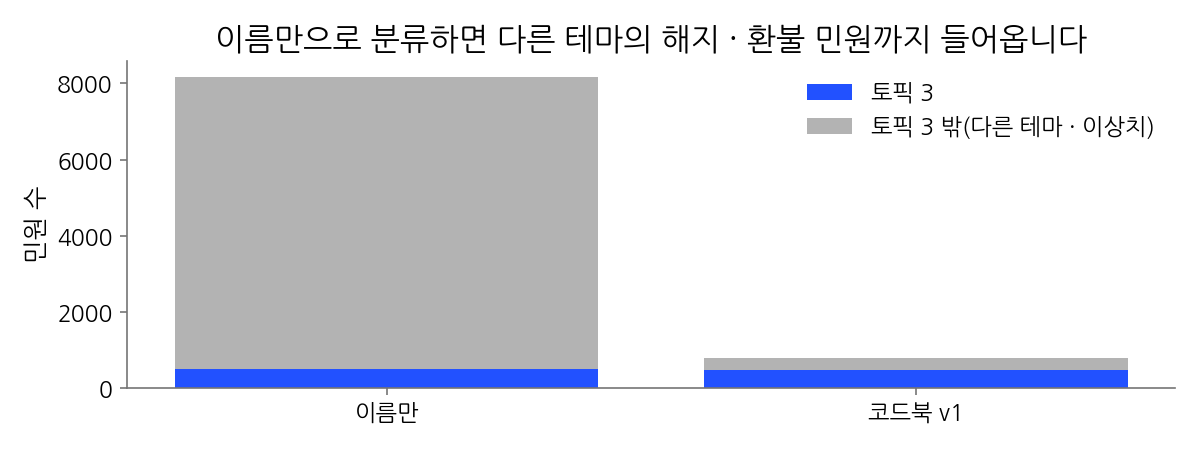

In [ ]:
# 1-5 ③ 그림: 두 기준으로 분류한 민원이 어느 토픽에서 왔는가
fig, ax = plt.subplots(figsize=(8, 3))
labels = ["이름만", "코드북 v1"]
in3 = [COMPARE_1.loc[0, "그 가운데 토픽 3"], COMPARE_1.loc[1, "그 가운데 토픽 3"]]
out3 = [COMPARE_1.loc[0, "토픽 3 밖"], COMPARE_1.loc[1, "토픽 3 밖"]]
ax.bar(labels, in3, color="#2251FF", label="토픽 3")
ax.bar(labels, out3, bottom=in3, color="#B3B3B3", label="토픽 3 밖(다른 테마 · 이상치)")
ax.set_ylabel("민원 수")
ax.legend(frameon=False)
ax.set_title("이름만으로 분류하면 다른 테마의 해지 · 환불 민원까지 들어옵니다")
plt.show()

이름만 있으면 휴대폰 · 여행 · 예식 같은 다른 테마의 해지 · 환불 민원까지 이 테마로 들어옵니다. 그러면 「헬스장 해지 민원이 몇 건인가」라는 질문에 답할 수 없습니다. 코드북 v1 은 시설과 사건을 함께 따지므로 분류한 민원의 절반 넘게 토픽 3 에서 옵니다.

코드북 v1 로 분류했지만 토픽 3 밖에 있는 민원의 수와 예를 출력합니다.

In [ ]:
# 1-5 ④ 코드북 v1 로 분류했지만 토픽 3 밖인 민원
outside = ALL[by_codebook & (ALL["토픽"] != 3)]
print(f"코드북 v1 로 분류했지만 토픽 3 밖인 민원 {len(outside)}건 · 그 가운데 이상치(토픽 -1) {int((outside['토픽'] == -1).sum())}건")
print("  예: " + " · ".join(outside["사건제목"].sample(4, random_state=0).tolist()))

코드북 v1 로 분류했지만 토픽 3 밖인 민원 327건 · 그 가운데 이상치(토픽 -1) 177건
  예: 필라테스 환불문의 · 요가학원 해지 문의 · 필라테스 중도 해지 과다한 위약금 부과를 함 · 필라테스 중도취소 대표자 변경한다고 하더니 대응없는 경우 문의


토픽 3 밖의 민원은 필라테스 · 요가 같은 운동 강습의 해지로, BERTopic 이 이상치(−1)나 다른 토픽에 배정한 민원입니다.

코드북 v1 의 기준으로 민원 한 건을 포함 · 제외로 나누는 함수 `classify_v1` 을 정의하고, 민원 두 건에 적용합니다.

In [ ]:
# 1-5 ⑤ 코드북 v1 의 분류 함수: 포함 · 제외(이유)
def classify_v1(title, item):
    is_facility = item in GYM_ITEMS or (re.search(SPORT_RE, title) is not None and item not in GOODS)
    is_event = re.search(EVENT_RE, title) is not None
    if is_facility and is_event:
        return "포함"
    if not is_facility:
        return "제외: 운동 시설이 아님 → 기타"
    return "제외: 해지 · 환불이 아님 → 기타"


print("「헬스장 중도해지시 환불 요청」 →", classify_v1("헬스장 중도해지시 환불 요청", "헬스장"))
print("「헬스장에서 핸드폰 틈사이 빠져서 문의」 →", classify_v1("헬스장에서 핸드폰 틈사이 빠져서 문의", "헬스장"))

「헬스장 중도해지시 환불 요청」 → 포함
「헬스장에서 핸드폰 틈사이 빠져서 문의」 → 제외: 해지 · 환불이 아님 → 기타


토픽 3 의 민원 전체에 `classify_v1` 을 적용해 포함 · 제외 건수를 계산합니다.

In [ ]:
# 1-5 ⑥ 토픽 3 민원을 코드북 v1 의 기준으로 나눈 결과
T3["코드북 v1"] = [classify_v1(t, i) for t, i in zip(T3["사건제목"], T3["품목명"])]
for k, v in T3["코드북 v1"].value_counts().items():
    print(f"{k}: {v}건 ({100 * v / len(T3):.1f}%)")

포함: 465건 (82.2%)
제외: 해지 · 환불이 아님 → 기타: 60건 (10.6%)
제외: 운동 시설이 아님 → 기타: 41건 (7.2%)


토픽 3 민원의 대부분은 포함 기준에 맞고, 나머지는 제외 기준에 따라 기타로 분류됩니다. 테마 건수는 토픽 배정으로 집계하고, 이 비율은 「토픽 3 을 이 이름으로 불러도 되는가」를 확인하는 값으로 씁니다.

### 1-6 결과 표: 테마 8개

코드북에서 정한 테마 이름으로 토픽 0～7 의 민원 수 · 비율 · 95% 구간을 계산합니다. 「원인」 열은 코드북의 원인 기준(제목에 「코로나」가 있으면 원인 「코로나」)을 적용한 비율입니다.

In [ ]:
# 1-6 ① 테마 8개의 건수 · 비율 · 95% 구간 · 원인 「코로나」 비율
N_ALL = len(SAMPLE)
rows = []
for k in THEMES:
    sel = (t0 == k)
    n = int(sel.sum())
    p = n / N_ALL
    half = 1.96 * np.sqrt(p * (1 - p) / N_ALL)
    corona = SAMPLE.loc[sel, "사건제목"].astype(str).str.contains("코로나").mean()
    rows.append({"테마(코드북 이름)": CB_ROWS[k]["테마"], "민원 수": n, "비율(%)": round(100 * p, 1),
                 "95% 구간(%)": f"{100 * (p - half):.1f}～{100 * (p + half):.1f}",
                 "원인 「코로나」(%)": round(100 * corona, 1), "예": CB_ROWS[k]["예"][0]})
THEME_TABLE = pd.DataFrame(rows).sort_values("민원 수", ascending=False).reset_index(drop=True)
display(THEME_TABLE)

,테마(코드북 이름),민원 수,비율(%),95% 구간(%),원인 「코로나」(%),예
0,통신·인터넷·광고 계약 해지와 요금,1525,7.6,7.3～8.0,0.0,휴대폰 가입 후 해지 문의(공)
1,여행·숙박·항공 취소 환불,1484,7.4,7.1～7.8,15.0,코로나로 운행중단된 항공권에 대한 환불
2,자동차·오토바이 구입·수리·렌트·보험,983,4.9,4.6～5.2,0.0,중고자동차 하부 부식과 운전석 도어 판금 도색 보상
3,헬스장·운동 강습 중도 해지 환불,566,2.8,2.6～3.1,5.7,휘트니스 계약 해지 관련 문의
4,정수기 렌탈 민원,478,2.4,2.2～2.6,0.0,코웨이 정수기 긴급수리요금감면 위면해지요청.
5,세탁·수선 사고(훼손·분실),472,2.4,2.1～2.6,0.0,세탁물 이염이 되어 보상 기준 문의
6,예식 취소·위약금,451,2.3,2.0～2.5,22.8,코로나로 인한 예식장해지문의
7,주식자문 계약,450,2.2,2.0～2.5,0.0,유사투자자문서비스 청약철회 시 위약금 문의


표의 숫자로 결론 문장을 만듭니다.

In [ ]:
# 1-6 ② 결론 한 문장
top = THEME_TABLE.iloc[0]
cor = THEME_TABLE.sort_values("원인 「코로나」(%)", ascending=False).iloc[0]
total = int(sum(THEME_TABLE["민원 수"]))
print(f"민원 2만 건 가운데 테마 8개에 속한 민원은 {total:,}건({100 * total / N_ALL:.1f}%)이다. "
      f"가장 큰 테마는 「{top['테마(코드북 이름)']}」 {top['민원 수']:,}건({top['비율(%)']}%)이고, "
      f"원인에 코로나가 적힌 비율은 「{cor['테마(코드북 이름)']}」이 {cor['원인 「코로나」(%)']}%로 가장 높다.")

민원 2만 건 가운데 테마 8개에 속한 민원은 6,409건(32.0%)이다. 가장 큰 테마는 「통신·인터넷·광고 계약 해지와 요금」 1,525건(7.6%)이고, 원인에 코로나가 적힌 비율은 「예식 취소·위약금」이 22.8%로 가장 높다.


## 2부 6일차: 리뷰 속성 코드북과 속성별 부정 비율

자료와 자료 준비 코드는 6일차 실습에서 가져왔습니다.

| 자료 | 쓰는 것 |
|---|---|
| 네이버 쇼핑 리뷰(bab2min/corpus, 별점 1 · 2 · 4 · 5점) | 20만 건 가운데 무작위 2만 건(시드 0)의 별점 · 본문 |
| Qwen3-4B 라벨(과정 결과) | 앞 1,000건의 속성 라벨 · 근거 텍스트 · 검증 상태 |
| 전임 담당자의 출력(과정 결과) | Qwen2.5-0.5B 가 앞 2,000건에 한 번씩 낸 원 출력 글 |

**자료 준비 ① 주소**: 패키지를 불러오고, 리뷰 원자료와 과정 결과(LLM 라벨) 파일을 받을 주소를 정합니다.

In [ ]:
# 자료 준비 ① 주소: 리뷰 원자료 · Qwen3-4B 라벨 · 전임 담당자의 출력을 받을 주소
# 모델은 호출하지 않고 과정 결과 파일을 읽은 뒤, 코드북 v1 과 검사 함수를 정의합니다
import os, re, json, math, time, hashlib, urllib.request
from decimal import Decimal, ROUND_HALF_UP
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_FILES = {
    "reviews": ("https://raw.githubusercontent.com/bab2min/corpus/master/sentiment/naver_shopping.txt",
                "naver_shopping.txt",
                "dc4d1aca0a148671cbe80bcb81962eee297370acab42be93c1617ce9336479c0",
                "https://github.com/bab2min/corpus/tree/master/sentiment"),
}
DATA_URL = "https://github.com/studio-js/korean-cx-text/raw/main/data"   # 과정 결과(LLM 라벨) 파일 주소
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"  # 원자료의 과정 복제본(원 출처와 같은 바이트)
SUBDIRS = ("", "cache", "raw", "processed")  # 자료 폴더 아래에서 찾는 차례

**자료 준비 ② 파일 찾기 · 받기 함수**: 1부 자료 준비 ② 의 함수를 다시 정의합니다. `nlp_data` 폴더에서 파일을 찾고, 없으면 받습니다.

In [ ]:
# 자료 준비 ② 파일 찾기 · 받기 함수
def data_dir():
    # 자료 최상위 폴더: 환경변수 NLP_DATA_DIR 이 있으면 그 폴더, 없으면 ./nlp_data
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    # 최상위 폴더 → cache/ → raw/ → processed/ 순서로 찾아 처음 나온 경로, 없으면 None
    for sub in SUBDIRS:
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    # 파일의 SHA-256 16진 문자열
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _download(url, path, retries=3):
    # url 을 path.part 로 받아 두고 성공하면 True (실패하면 세 번까지 다시 시도)
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    for i in range(retries):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            return True
        except Exception as e:  # network error: retry
            print(f"받기 실패 {i + 1}/{retries}: {e}")
            time.sleep(2 * (i + 1))
    return False

**자료 준비 ③ 원자료 · 과정 결과 받기 함수**: 받은 원자료를 SHA-256 으로 확인하는 함수와 과정 결과를 받는 함수를 정의합니다. `rnd` 는 반올림 함수입니다.

In [ ]:
# 자료 준비 ③ 원자료 · 과정 결과 받기 함수
def _fetch(url, name, sha=None, strict=False):
    # 로컬에 있으면 그 경로, 없으면 url 에서 받아 SHA-256 확인 뒤 최상위 폴더/cache/ 에 두고 경로를 반환함
    path = find_local(name)
    if path is None:
        path = os.path.join(data_dir(), "cache", name)
        if not _download(url, path):
            return None
        if strict and sha and sha256_of(path + ".part") != sha:
            os.remove(path + ".part")
            raise RuntimeError(f"받은 {name} 의 SHA-256 이 맞지 않습니다. 다시 실행해 보세요.")
        os.replace(path + ".part", path)
    return path


def fetch_raw(name):
    # 원자료 경로: 로컬을 먼저 보고, 없으면 과정 복제본(MIRROR_URL) → 원 출처 URL 순서로 받음
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = _fetch(f"{MIRROR_URL}/{fname}", fname)
        if path is not None and sha256_of(path) != sha:  # 복제본이 다르면 버리고 원 출처로
            os.remove(path)
            path = None
    if path is None:
        path = _fetch(url, fname)
    if path is None:
        raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 본문의 수와 다를 수 있습니다(데이터 페이지: {page})")
    return path


def fetch_precomputed(name, sha=None):
    # 과정 결과 파일 경로: 로컬을 먼저 보고, 없으면 DATA_URL/name 에서 받음(sha 를 주면 맞지 않을 때 멈춤)
    path = _fetch(f"{DATA_URL}/{name}", name, sha, strict=True)
    if path is None:
        raise RuntimeError(f"과정 결과 파일 {name} 을 받지 못했습니다. 이 파일은 다른 경로로 만들 수 없습니다."
                           " 강사에게 받은 파일을 이 노트북과 같은 폴더의 nlp_data/ 에 두고 이 셀을 다시 실행합니다")
    return path


def rnd(x, digits):
    # 십진 값 기준 반올림(끝자리 5 는 올림): 본문의 수와 같은 반올림 방식
    x = float(x)
    if not math.isfinite(x):
        return x
    return float(Decimal(f"{x:.12g}").quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))

**자료 준비 ④ 코드북 v1**: 속성 6개(`ASPECTS`)와 극성 3가지(`POLARITIES`)를 정의합니다. 속성마다 정의 · 포함 기준 · 제외 기준(`CODEBOOK_V1`)과 경계 기준(`BOUNDARY_RULE`)도 정의합니다. LLM 에 보낸 프롬프트도 이 표로 만들었습니다.

In [ ]:
# 자료 준비 ④ 코드북 v1
ASPECTS = ["배송", "품질", "사이즈", "가격", "교환/환불", "기타"]
POLARITIES = ["긍정", "부정", "중립"]
OVERALL = ["긍정", "부정"]

# 리뷰 속성 코드북 v1: 속성마다 이름 · 정의 · 포함 기준 · 제외 기준
CODEBOOK_V1 = [
    {"속성": "배송", "정의": "주문한 물건이 도착하기까지의 과정",
     "포함": "속도·지연, 택배, 포장·박스 상태, 오배송",
     "제외": "제품 자체의 흠집·불량(→ 품질)"},
    {"속성": "품질", "정의": "제품 자체의 상태와 성능",
     "포함": "불량, 마감, 내구성, 맛·신선도, 성능, 디자인",
     "제외": "크기·치수(→ 사이즈), 포장 상태(→ 배송)"},
    {"속성": "사이즈", "정의": "크기·길이·치수가 맞는지",
     "포함": "크기, 길이, 핏, 양",
     "제외": "무게감·두께 같은 재질 느낌(→ 품질)"},
    {"속성": "가격", "정의": "값과 가성비",
     "포함": "싸다·비싸다, 가성비, 할인",
     "제외": "환불 금액(→ 교환/환불)"},
    {"속성": "교환/환불", "정의": "교환·반품·환불·취소 절차",
     "포함": "교환·반품, 환불, 주문 취소",
     "제외": "처음 배송 지연(→ 배송)"},
    {"속성": "기타", "정의": "위 다섯에 들지 않는 구체적 평가",
     "포함": "판매자 응대, 사은품 등",
     "제외": "속성이 드러나지 않는 감탄(예: 좋아요)은 라벨 없음"},
]
BOUNDARY_RULE = "박스·포장 파손은 배송, 제품 자체의 흠집·불량은 품질."

**자료 준비 ⑤ JSON 스키마**: LLM 이 답할 JSON 의 형식(`SCHEMA_V1`)입니다. 어떤 키가 있어야 하고, 속성 · 극성에 어떤 값만 허용하는지 정합니다.

In [ ]:
# JSON 스키마: 출력이 지켜야 할 키와 허용 목록
SCHEMA_V1 = {
    "type": "object",
    "required": ["overall", "aspects"],
    "properties": {
        "overall": {"enum": OVERALL},
        "aspects": {
            "type": "array",
            "items": {
                "type": "object",
                "required": ["aspect", "polarity", "evidence"],
                "properties": {
                    "aspect": {"enum": ASPECTS},
                    "polarity": {"enum": POLARITIES},
                    "evidence": {"type": "string"},
                },
            },
        },
    },
}

**자료 준비 ⑥ JSON 추출 함수**: `extract_json(원 출력)` 은 모델의 출력 글에서 JSON 부분만 추출합니다. 앞뒤에 코드 펜스 ``` 가 있어도 추출합니다.

In [ ]:
# 자료 준비 ⑥ JSON 추출 함수
def extract_json(raw):
    """First {...} block that parses; None if none."""
    s = raw.strip()
    s = re.sub(r"^```(?:json)?\s*|\s*```$", "", s)
    start = s.find("{")
    while start != -1:
        depth = 0
        for i in range(start, len(s)):
            if s[i] == "{":
                depth += 1
            elif s[i] == "}":
                depth -= 1
                if depth == 0:
                    try:
                        return json.loads(s[start:i + 1])
                    except json.JSONDecodeError:
                        break
        start = s.find("{", start + 1)
    return None

**자료 준비 ⑦ 스키마 검사 함수**: `schema_errors(JSON)` 은 추출한 JSON 이 스키마를 지키는지 검사하고, 어긴 곳을 목록으로 반환합니다.

In [ ]:
# 자료 준비 ⑦ 스키마 검사 함수
def schema_errors(obj, schema=SCHEMA_V1):
    """Small validator for this schema family (object / array / enum / string / required)."""
    errs = []

    def walk(x, sch, path):
        if "enum" in sch:
            if x not in sch["enum"]:
                errs.append(f"{path} 값 {x!r} 는 허용 목록 밖")
            return
        t = sch.get("type")
        if t == "object":
            if not isinstance(x, dict):
                errs.append(f"{path} 는 객체여야 함")
                return
            for k in sch.get("required", []):
                if k not in x:
                    errs.append(f"{path}.{k} 없음")
            for k, sub in sch.get("properties", {}).items():
                if k in x:
                    walk(x[k], sub, f"{path}.{k}")
        elif t == "array":
            if not isinstance(x, list):
                errs.append(f"{path} 는 목록이어야 함")
                return
            for i, item in enumerate(x):
                walk(item, sch["items"], f"{path}[{i}]")
        elif t == "string" and not isinstance(x, str):
            errs.append(f"{path} 는 문자열이어야 함")

    walk(obj, schema, "$")
    return errs

**자료 준비 ⑧ 근거 확인 · 출력 검사 함수**: `evidence_in_text(근거, 원문)` 은 근거 텍스트가 원문에 글자 그대로 있는지 확인합니다. `check_output(원 출력, 원문)` 은 JSON 추출과 스키마 검사를 한 번에 해서 통과 여부를 반환합니다.

In [ ]:
# 자료 준비 ⑧ 근거 확인 · 출력 검사 함수
def _squash(s):
    return re.sub(r"\s+", " ", s).strip()


def evidence_in_text(evidence, text):
    """Evidence must be a non-empty substring of the original review (whitespace runs collapsed)."""
    if not isinstance(evidence, str):
        return False
    ev = _squash(evidence)
    return bool(ev) and ev in _squash(text)


def check_output(raw, text, schema=SCHEMA_V1):
    """-> dict(parsed, errors, ok). ok = parsed and schema-valid."""
    obj = extract_json(raw)
    if obj is None:
        return {"parsed": None, "errors": ["JSON 파싱 실패"], "ok": False}
    errs = schema_errors(obj, schema)
    return {"parsed": obj, "errors": errs, "ok": not errs}

**자료 준비 ⑨ 리뷰와 Qwen3-4B 라벨 읽기**: 리뷰 20만 건에서 표본 2만 건을 뽑습니다. 앞 1,000건의 라벨(`LABELS_1000`)은 행 번호로 합칩니다. 라벨 한 개는 속성 · 극성 · 근거 텍스트 · 근거 확인 여부(`evidence_ok`)입니다.

In [ ]:
# 리뷰 20만 건(별점 → 별점 극성)과 리뷰 표본 2만 건(시드 0, 표본 안의 차례 = rank)
_rows = [ln.split("\t", 1) for ln in open(fetch_raw("reviews"), encoding="utf-8").read().split("\n") if ln]
REVIEWS = pd.DataFrame(_rows, columns=["별점", "본문"])
REVIEWS.insert(0, "row_id", range(len(REVIEWS)))                 # 원자료의 행 번호(0부터)
REVIEWS["별점"] = REVIEWS["별점"].astype(int)
REVIEWS["극성"] = np.where(REVIEWS["별점"] <= 2, "부정", "긍정")   # 별점 극성: 1·2점 부정, 4·5점 긍정
SAMPLE = REVIEWS.sample(n=20000, random_state=0).reset_index(drop=True)
SAMPLE.insert(1, "rank", range(len(SAMPLE)))

# Qwen3-4B 라벨(과정 결과): 2만 건의 선택형 극성(overall)과 앞 1,000건의 속성 라벨
_lab = pd.read_parquet(fetch_precomputed("llm_review_labels.parquet"))
MODEL_INFO = f"{_lab['model'].iloc[0].split('/')[-1]}(버전 {_lab['model_revision'].iloc[0][:8]})"
OVERALL_20K = _lab[["row_id", "overall"]].merge(SAMPLE[["row_id", "별점", "극성"]], on="row_id")
LABELS_1000 = (_lab.loc[_lab["aspects_done"], ["row_id", "status", "tries", "aspects_json"]]
               .merge(SAMPLE[["row_id", "rank", "별점", "극성", "본문"]], on="row_id")
               .sort_values("rank").reset_index(drop=True))
LABELS_1000["status"] = LABELS_1000["status"].replace({"재요청 통과": "재시도 통과"})   # 상태값 이름을 본문과 같게
LABELS_1000["labels"] = LABELS_1000["aspects_json"].map(json.loads)   # 리뷰마다 라벨 목록(속성 · 극성 · 근거 텍스트 · evidence_ok)
LABELS_1000["tries"] = LABELS_1000["tries"].astype(int)

**자료 준비 ⑩ 전임 담당자의 출력 읽기**: Qwen2.5-0.5B 의 원 출력 2,000건(`PRED`)을 읽고 요약을 출력합니다. `N_SENT` 는 모델에 보낸 리뷰 수입니다.

In [ ]:
# 전임 담당자의 출력(과정 결과): Qwen2.5-0.5B 가 앞 2,000건에 한 번씩 낸 원 출력 글. 재시도는 없었습니다
_pred = pd.read_parquet(fetch_precomputed("llm_review_predecessor.parquet"))
PRED = (_pred[["row_id", "raw", "model"]].merge(SAMPLE[["row_id", "rank", "별점", "본문"]], on="row_id")
        .sort_values("rank").reset_index(drop=True))
N_SENT = len(PRED)                                                # 전임 담당자가 모델에 보낸 리뷰 수

_st = LABELS_1000["status"].value_counts()
print(f"준비 끝: Qwen3-4B 라벨 리뷰 {len(LABELS_1000):,}건 · 전임 담당자의 출력 {N_SENT:,}건")
print(f"리뷰 {len(REVIEWS):,}건 → 리뷰 표본 {len(SAMPLE):,}건(시드 0) · 선택형 극성 {OVERALL_20K['overall'].notna().sum():,}건")
print(f"속성 라벨: 표본의 앞 {len(LABELS_1000):,}건 · 모델 {MODEL_INFO} · 프롬프트 버전 aspect-v1")
print(f"검증 상태: 통과 {_st.get('통과', 0)}건 · 재시도 통과 {_st.get('재시도 통과', 0)}건 · 라벨 실패 {_st.get('기타', 0)}건")
print(f"전임 담당자: {PRED['model'].iloc[0].split('/')[-1]} · 표본의 앞 {N_SENT:,}건 · 재시도 없음")
print("코드북 v1 의 속성 6개: " + " · ".join(ASPECTS))
print("Qwen3-4B 의 라벨은 정답이 아니라 모델 하나의 판단입니다")

준비 끝: Qwen3-4B 라벨 리뷰 1,000건 · 전임 담당자의 출력 2,000건
리뷰 200,000건 → 리뷰 표본 20,000건(시드 0) · 선택형 극성 20,000건
속성 라벨: 표본의 앞 1,000건 · 모델 Qwen3-4B-Instruct-2507(버전 cdbee75f) · 프롬프트 버전 aspect-v1
검증 상태: 통과 873건 · 재시도 통과 108건 · 라벨 실패 19건
전임 담당자: Qwen2.5-0.5B-Instruct · 표본의 앞 2,000건 · 재시도 없음
코드북 v1 의 속성 6개: 배송 · 품질 · 사이즈 · 가격 · 교환/환불 · 기타
Qwen3-4B 의 라벨은 정답이 아니라 모델 하나의 판단입니다


### 2-1 코드북 v1

리뷰 한 건의 라벨은 (속성, 극성) 쌍입니다. 코드북 v1 의 표와 LLM 이 답할 JSON 의 예를 출력합니다.

In [ ]:
# 2-1 코드북 v1 표와 JSON 예
display(pd.DataFrame(CODEBOOK_V1).rename(columns={"포함": "포함 기준", "제외": "제외 기준"}))
print("경계 기준:", BOUNDARY_RULE)
print("극성:", " · ".join(POLARITIES))
print('JSON 예: {"overall":"부정","aspects":[{"aspect":"배송","polarity":"긍정","evidence":"배송은 빠른데"},'
      '{"aspect":"품질","polarity":"부정","evidence":"바느질이 엉성해요"}]}')

,속성,정의,포함 기준,제외 기준
0,배송,주문한 물건이 도착하기까지의 과정,"속도·지연, 택배, 포장·박스 상태, 오배송",제품 자체의 흠집·불량(→ 품질)
1,품질,제품 자체의 상태와 성능,"불량, 마감, 내구성, 맛·신선도, 성능, 디자인","크기·치수(→ 사이즈), 포장 상태(→ 배송)"
2,사이즈,크기·길이·치수가 맞는지,"크기, 길이, 핏, 양",무게감·두께 같은 재질 느낌(→ 품질)
3,가격,값과 가성비,"싸다·비싸다, 가성비, 할인",환불 금액(→ 교환/환불)
4,교환/환불,교환·반품·환불·취소 절차,"교환·반품, 환불, 주문 취소",처음 배송 지연(→ 배송)
5,기타,위 다섯에 들지 않는 구체적 평가,"판매자 응대, 사은품 등",속성이 드러나지 않는 감탄(예: 좋아요)은 라벨 없음


경계 기준: 박스·포장 파손은 배송, 제품 자체의 흠집·불량은 품질.
극성: 긍정 · 부정 · 중립
JSON 예: {"overall":"부정","aspects":[{"aspect":"배송","polarity":"긍정","evidence":"배송은 빠른데"},{"aspect":"품질","polarity":"부정","evidence":"바느질이 엉성해요"}]}


### 2-2 코드북이 프롬프트가 되는 과정

코드북 표는 그대로 LLM 에 보내는 지시문(시스템 프롬프트)이 됩니다. 6일차 실습처럼 코드북 표에서 프롬프트 글을 만들어 출력합니다.

In [ ]:
# 2-2 ① 코드북 표 → 시스템 프롬프트
def codebook_text(codebook=CODEBOOK_V1):
    return "\n".join(f"- {r['속성']}: {r['정의']}({r['포함']})" for r in codebook)


SYSTEM_PROMPT = (
    "쇼핑 리뷰를 리뷰 속성 코드북 v1 으로 라벨합니다.\n" + codebook_text() + "\n"
    "경계: " + BOUNDARY_RULE + "\n"
    "규칙: overall 은 리뷰 전체 극성(긍정/부정). aspects 는 평가한 속성마다 한 항목, "
    "polarity 는 긍정/부정/중립. evidence 는 판단 근거가 된 짧은 구절(두세 어절)을 리뷰 원문에서 글자 그대로 복사(고치거나 요약하지 않음). "
    "속성이 없으면 aspects 는 []. JSON 한 개만 답합니다."
)
print(SYSTEM_PROMPT)

쇼핑 리뷰를 리뷰 속성 코드북 v1 으로 라벨합니다.
- 배송: 주문한 물건이 도착하기까지의 과정(속도·지연, 택배, 포장·박스 상태, 오배송)
- 품질: 제품 자체의 상태와 성능(불량, 마감, 내구성, 맛·신선도, 성능, 디자인)
- 사이즈: 크기·길이·치수가 맞는지(크기, 길이, 핏, 양)
- 가격: 값과 가성비(싸다·비싸다, 가성비, 할인)
- 교환/환불: 교환·반품·환불·취소 절차(교환·반품, 환불, 주문 취소)
- 기타: 위 다섯에 들지 않는 구체적 평가(판매자 응대, 사은품 등)
경계: 박스·포장 파손은 배송, 제품 자체의 흠집·불량은 품질.
규칙: overall 은 리뷰 전체 극성(긍정/부정). aspects 는 평가한 속성마다 한 항목, polarity 는 긍정/부정/중립. evidence 는 판단 근거가 된 짧은 구절(두세 어절)을 리뷰 원문에서 글자 그대로 복사(고치거나 요약하지 않음). 속성이 없으면 aspects 는 []. JSON 한 개만 답합니다.


LLM 은 리뷰마다 JSON 한 개를 답하고, 그 JSON 의 aspects 가 라벨이 됩니다. 저장된 원 출력 한 건을 검사해 라벨로 바꿉니다. Qwen3-4B 의 저장 결과에는 원 출력 글이 없어, 원 출력이 남은 전임 담당자(Qwen2.5-0.5B)의 출력을 씁니다.

In [ ]:
# 2-2 ② 리뷰 한 건: 원 출력 → 형식 검사 → 근거 확인 → 라벨
r = PRED.set_index("row_id").loc[1906]
print("리뷰 원문:", r["본문"])
print("모델의 원 출력:", " ".join(r["raw"].split()))
chk = check_output(r["raw"], r["본문"])
print("형식 검사(JSON 파싱 · 허용 목록):", "통과" if chk["ok"] else "어김 · " + "; ".join(chk["errors"][:2]))
if chk["ok"]:
    for x in chk["parsed"]["aspects"]:
        ok = evidence_in_text(x["evidence"], r["본문"])
        print(f"라벨 ({x['aspect']}, {x['polarity']}) · 근거 「{x['evidence']}」 · 근거가 원문에 있음: {'예' if ok else '아니오(보류)'}")
print("근거가 원문에 있는 라벨만 2-6 의 비율 집계에 들어갑니다")

리뷰 원문: 배송도 늦고..쿠션은 출렁거리고..
모델의 원 출력: {"overall":"부정","aspects":[{"aspect":"배송","polarity":"부정","evidence":"배송도 늦고"},{"aspect":"품질","polarity":"부정","evidence":"쿠션은 출렁거리고"}]}
형식 검사(JSON 파싱 · 허용 목록): 통과
라벨 (배송, 부정) · 근거 「배송도 늦고」 · 근거가 원문에 있음: 예
라벨 (품질, 부정) · 근거 「쿠션은 출렁거리고」 · 근거가 원문에 있음: 예
근거가 원문에 있는 라벨만 2-6 의 비율 집계에 들어갑니다


### 2-3 코드북으로 리뷰 5건 라벨하기

리뷰 5건마다 코드북의 포함 기준에 맞춰 정한 라벨과 그 근거가 된 기준을 함께 출력합니다.

In [ ]:
# 2-3 ① 리뷰 5건의 예시 라벨과 이유
EXAMPLE = {
    161542: ([("배송", "긍정"), ("품질", "부정"), ("가격", "긍정")],
             "배송빠르고 → 배송(속도). 좀 부실하긴 → 품질(내구성). 가격대비 좋아요 → 가격(가성비)"),
    43403: ([("배송", "부정"), ("품질", "긍정")],
            "포장이 아쉬우나 → 배송(포함 기준: 포장·박스 상태). 맛은 좋아요 → 품질(맛·신선도)"),
    32284: ([("품질", "부정")],
            "무엇이 찌그러졌는지 원문에 없음 → 제품이 찌그러진 것으로 보고 품질. 「귀찮아서 그냥 씁니다」는 가격의 포함 기준에 맞는 말이 없어 라벨 없음"),
    144586: ([], "감탄만 있음(무엇이 좋은지 없음) → 기타의 제외 기준대로 라벨 없음. 별점은 2점이라 글과 별점이 엇갈림"),
    37400: ([("교환/환불", "부정")], "교환이 늦었네요 → 교환/환불(교환·반품 절차)"),
}
for rid, (labs, why) in EXAMPLE.items():
    print(f"리뷰 {rid}: " + (" ".join(f"({a}, {p})" for a, p in labs) or "라벨 없음") + f"  ← {why}")

리뷰 161542: (배송, 긍정) (품질, 부정) (가격, 긍정)  ← 배송빠르고 → 배송(속도). 좀 부실하긴 → 품질(내구성). 가격대비 좋아요 → 가격(가성비)
리뷰 43403: (배송, 부정) (품질, 긍정)  ← 포장이 아쉬우나 → 배송(포함 기준: 포장·박스 상태). 맛은 좋아요 → 품질(맛·신선도)
리뷰 32284: (품질, 부정)  ← 무엇이 찌그러졌는지 원문에 없음 → 제품이 찌그러진 것으로 보고 품질. 「귀찮아서 그냥 씁니다」는 가격의 포함 기준에 맞는 말이 없어 라벨 없음
리뷰 144586: 라벨 없음  ← 감탄만 있음(무엇이 좋은지 없음) → 기타의 제외 기준대로 라벨 없음. 별점은 2점이라 글과 별점이 엇갈림
리뷰 37400: (교환/환불, 부정)  ← 교환이 늦었네요 → 교환/환불(교환·반품 절차)


이 라벨을 같은 코드북을 받은 Qwen3-4B 의 라벨과 나란히 비교합니다. Qwen3-4B 의 라벨은 정답이 아니라 모델 하나의 판단입니다.

In [ ]:
# 2-3 ② 예시 라벨과 Qwen3-4B 라벨 비교
BY_ID = LABELS_1000.set_index("row_id")
rows = []
for rid, (labs, why) in EXAMPLE.items():
    r = BY_ID.loc[rid]
    qwen = sorted({(x["aspect"], x["polarity"]) for x in r["labels"]})
    rows.append({"리뷰": rid, "별점": r["별점"], "원문": r["본문"],
                 "예시 라벨": " ".join(f"({a}, {p})" for a, p in labs) or "없음",
                 "Qwen3-4B": " ".join(f"({a}, {p})" for a, p in qwen) or "없음",
                 "같음": set(labs) == set(qwen)})
STEP_TABLE = pd.DataFrame(rows)
display(STEP_TABLE)
print(f"5건 가운데 {int(STEP_TABLE['같음'].sum())}건이 Qwen3-4B 와 같습니다")

,리뷰,별점,원문,예시 라벨,Qwen3-4B,같음
0,161542,5,배송빠르고 좀 부실하긴 하지만 가격대비 좋아요,"(배송, 긍정) (품질, 부정) (가격, 긍정)","(가격, 긍정) (배송, 긍정) (품질, 부정)",True
1,43403,2,포장이 많이 아쉬우나 맛은좋아요,"(배송, 부정) (품질, 긍정)","(배송, 부정) (품질, 긍정)",True
2,32284,2,찌그러져서 왔어요 귀찮아서 그냥 씁니다,"(품질, 부정)","(가격, 중립) (품질, 부정)",False
3,144586,2,만족해요 추천 추천,없음,없음,True
4,37400,1,교환이 너무 늦었네요 ㅜ,"(교환/환불, 부정)","(교환/환불, 부정)",True


5건 가운데 4건이 Qwen3-4B 와 같습니다


Qwen3-4B 와 라벨이 다른 리뷰는 32284 하나입니다. Qwen3-4B 는 「귀찮아서 그냥 씁니다」를 (가격, 중립)으로 라벨했습니다. 그런데 코드북의 가격 포함 기준(싸다 · 비싸다, 가성비, 할인)에 맞는 말이 없습니다. 「찌그러졌다」고만 하고 무엇이 찌그러졌는지 원문에 없는 리뷰는 판단이 갈립니다. 이런 리뷰는 그 결정을 코드북의 포함 기준에 더합니다(예: 「찌그러진 대상이 원문에 없으면 품질」). 그래야 다음 사람도 같은 라벨을 정합니다.

### 2-4 LLM 출력 확인

LLM 의 출력은 글이라 집계 전에 형식과 근거 텍스트를 확인합니다.

- **형식**: JSON 으로 읽히는가, 속성 · 극성이 코드북의 허용 목록 안인가. 어기면 그 출력은 라벨 실패입니다.
- **근거 텍스트**: 라벨마다 근거 텍스트가 원문에 글자 그대로 있는가. 없으면 그 라벨을 보류하고 집계에서 뺍니다.

6일차 실습의 출력 6건에 검사 함수를 적용한 결과를 표로 출력합니다.

In [ ]:
# 2-4 출력 6건의 형식 · 근거 확인
STEP2_IDS = [1906, 161542, 43403, 32284, 144586, 37400]
P6 = PRED.set_index("row_id").loc[STEP2_IDS].reset_index()
rows = []
for i, r in P6.iterrows():
    chk = check_output(r["raw"], r["본문"])
    if not chk["ok"]:
        rows.append({"출력": i + 1, "리뷰": r["row_id"], "형식": "어김", "보류한 라벨": "-", "이유": "; ".join(chk["errors"][:2])})
        continue
    held = [x["aspect"] for x in chk["parsed"]["aspects"] if not evidence_in_text(x["evidence"], r["본문"])]
    rows.append({"출력": i + 1, "리뷰": r["row_id"], "형식": "통과", "보류한 라벨": ", ".join(held) or "없음",
                 "이유": "근거 텍스트가 원문에 없음" if held else "근거 텍스트가 모두 원문에 있음"})
display(pd.DataFrame(rows))

,출력,리뷰,형식,보류한 라벨,이유
0,1,1906,통과,없음,근거 텍스트가 모두 원문에 있음
1,2,161542,어김,-,JSON 파싱 실패
2,3,43403,어김,-,$.aspects[0].aspect 값 '포장' 는 허용 목록 밖; $.aspects[1].aspect 값 '맛' 는 허용 목록 밖
3,4,32284,통과,없음,근거 텍스트가 모두 원문에 있음
4,5,144586,통과,"배송, 품질",근거 텍스트가 원문에 없음
5,6,37400,어김,-,$.aspects[0].aspect 값 '교환' 는 허용 목록 밖


### 2-5 경계 기준이 있을 때와 없을 때

코드북의 경계 기준 「박스 · 포장 파손은 배송, 제품 자체의 흠집 · 불량은 품질」이 결과를 얼마나 바꾸는지 봅니다. 리뷰 1,000건에서 근거 텍스트에 「포장 · 박스 · 상자」가 있는 라벨의 속성별 건수를 집계합니다.

In [ ]:
# 2-5 ① 근거 텍스트에 포장 · 박스 · 상자가 있는 라벨의 속성
PACK_RE = r"포장|박스|상자"
pack = [(x["aspect"], x["polarity"]) for labs in LABELS_1000["labels"] for x in labs
        if x["evidence_ok"] and re.search(PACK_RE, x["evidence"])]
print(f"근거 텍스트에 포장 · 박스 · 상자가 있는 라벨 {len(pack)}개")
print(pd.Series([a for a, _ in pack]).value_counts().to_string())

근거 텍스트에 포장 · 박스 · 상자가 있는 라벨 29개
배송       16
품질        6
가격        3
교환/환불     2
사이즈       1
기타        1


부정 리뷰 수를 집계하는 함수 `neg_reviews` 를 정의합니다. 한 리뷰에 부정 라벨이 2개여도 한 건으로 집계하고, 근거가 확인된 라벨만 씁니다. `relabel` 을 주면 라벨의 속성을 바꿔서 집계합니다.

- **코드북대로**: 저장된 라벨 그대로(포장 불만은 배송)
- **코드북 없이(가정)**: 경계 기준이 없어 포장 불만을 품질로 본 경우

In [ ]:
# 2-5 ② 부정 리뷰 수 집계 함수와 「코드북 없이」 가정
def neg_reviews(df, aspect, relabel=None):
    """그 속성의 근거 확인 부정 라벨이 하나라도 있는 리뷰 수(한 리뷰는 한 번). relabel 은 라벨 속성을 바꾸는 함수"""
    n = 0
    for labs in df["labels"]:
        hit = False
        for x in labs:
            a = relabel(x) if relabel else x["aspect"]
            if a == aspect and x["polarity"] == "부정" and x["evidence_ok"]:
                hit = True
        n += hit
    return n


def pack_to_quality(x):
    # 코드북 없이(가정): 근거에 포장 · 박스 · 상자가 있으면 품질로 본다
    return "품질" if re.search(PACK_RE, x["evidence"]) else x["aspect"]


N = len(LABELS_1000)                                              # 분모: LLM 에 보낸 리뷰 수(라벨 실패 포함)
print("보낸 리뷰", N, "건")

보낸 리뷰 1000 건


배송 · 품질의 부정 비율을 두 방식으로 계산해 비교합니다.

In [ ]:
# 2-5 ③ 코드북대로 · 코드북 없이(가정)의 배송 · 품질 부정 비율
rows = []
for a in ["배송", "품질"]:
    k1, k2 = neg_reviews(LABELS_1000, a), neg_reviews(LABELS_1000, a, pack_to_quality)
    rows.append({"속성": a, "코드북대로 부정 리뷰": k1, "코드북대로(%)": round(100 * k1 / N, 1),
                 "코드북 없이(가정) 부정 리뷰": k2, "코드북 없이(%)": round(100 * k2 / N, 1),
                 "차이(%p)": round(100 * (k2 - k1) / N, 1)})
COMPARE_2 = pd.DataFrame(rows)
display(COMPARE_2)
d1, d2 = COMPARE_2.loc[0, "코드북대로 부정 리뷰"], COMPARE_2.loc[0, "코드북 없이(가정) 부정 리뷰"]
print(f"배송 부정 리뷰 {d1}건 가운데 {d1 - d2}건({100 * (d1 - d2) / d1:.0f}%)이 포장 불만입니다. "
      f"경계 기준이 없으면 이 {d1 - d2}건이 품질로 분류되어 배송 불만에서 빠집니다")

,속성,코드북대로 부정 리뷰,코드북대로(%),코드북 없이(가정) 부정 리뷰,코드북 없이(%),차이(%p)
0,배송,75,7.5,64,6.4,-1.1
1,품질,358,35.8,365,36.5,0.7


배송 부정 리뷰 75건 가운데 11건(15%)이 포장 불만입니다. 경계 기준이 없으면 이 11건이 품질로 분류되어 배송 불만에서 빠집니다


경계 기준이 없으면 포장 불만이 품질 불만으로 분류되어 배송 부정 비율은 줄고 품질 부정 비율은 늘어납니다. 품질 부정 비율은 원래 커서 차이가 작아 보이지만, 배송 부정 비율에서는 포장 불만이 모두 빠집니다. 코드북은 사람마다, 또 LLM 호출마다 같은 리뷰를 같은 속성으로 나누게 하는 기준입니다.

### 2-6 결과 표: 속성별 부정 비율과 95% 구간

비율은 「리뷰 몇 건 가운데 몇 건」입니다.

- **분모**: LLM 에 보낸 리뷰 수 1,000건. 라벨 실패 리뷰도 보낸 리뷰라 분모에 남습니다.
- **분자**: 근거가 확인된 부정 라벨이 하나라도 있는 리뷰 수. 보류한 라벨은 빼고, 한 리뷰에 부정 라벨이 2개여도 한 건입니다.

속성마다 비율과 95% 구간을 계산하는 함수 `aspect_table` 을 정의하고 표를 만듭니다.

In [ ]:
# 2-6 ① 속성별 부정 비율과 95% 구간 표
def aspect_table(df):
    n = len(df)
    k = np.array([neg_reviews(df, a) for a in ASPECTS])
    p = k / n
    half = 1.96 * np.sqrt(p * (1 - p) / n)                       # 오차 한계
    t = pd.DataFrame({"속성": ASPECTS, "부정 리뷰": k, "비율(%)": np.round(100 * p, 1),
                      "아래(%)": np.round(np.maximum(0, 100 * (p - half)), 1), "위(%)": np.round(100 * (p + half), 1)})
    return t.sort_values("비율(%)", ascending=False).reset_index(drop=True)


ALL_TABLE = aspect_table(LABELS_1000)
print(f"보낸 리뷰 {N}건 · 라벨 실패 {int((LABELS_1000['status'] == '기타').sum())}건(분모에 포함)")
display(ALL_TABLE)

보낸 리뷰 1000건 · 라벨 실패 19건(분모에 포함)


,속성,부정 리뷰,비율(%),아래(%),위(%)
0,품질,358,35.8,32.8,38.8
1,사이즈,92,9.2,7.4,11.0
2,배송,75,7.5,5.9,9.1
3,가격,50,5.0,3.6,6.4
4,교환/환불,38,3.8,2.6,5.0
5,기타,22,2.2,1.3,3.1


표를 그림으로 그립니다. 점이 비율이고 가로 막대가 95% 구간입니다.

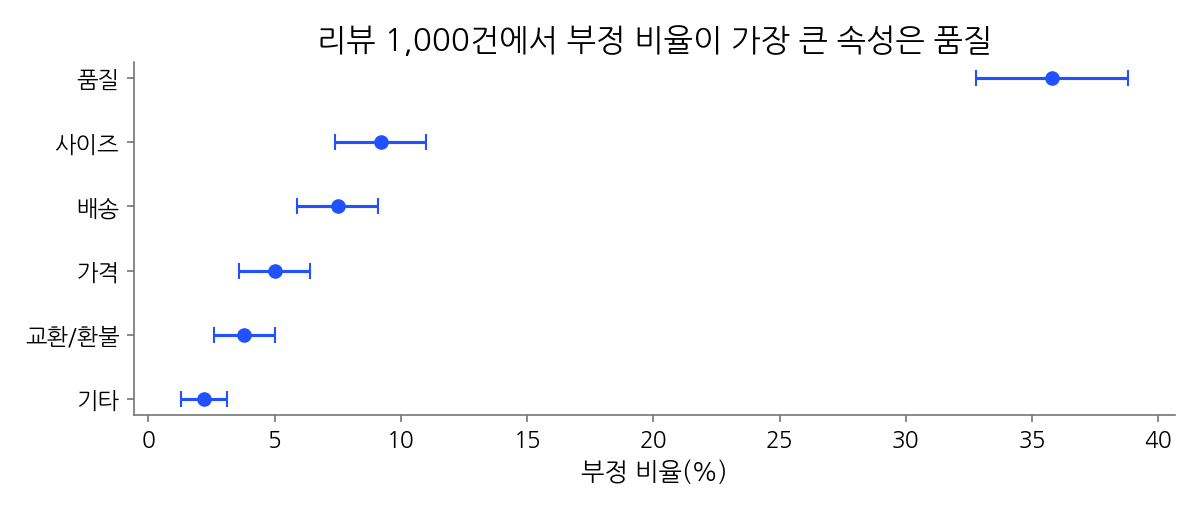

In [ ]:
# 2-6 ② 그림: 속성별 부정 비율과 95% 구간
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.errorbar(ALL_TABLE["비율(%)"], ALL_TABLE["속성"],
            xerr=[ALL_TABLE["비율(%)"] - ALL_TABLE["아래(%)"], ALL_TABLE["위(%)"] - ALL_TABLE["비율(%)"]],
            fmt="o", capsize=4, color="#2251FF")
ax.invert_yaxis()
ax.set_xlabel("부정 비율(%)")
ax.set_title("리뷰 1,000건에서 부정 비율이 가장 큰 속성은 " + ALL_TABLE.loc[0, "속성"])
plt.show()

분모나 분자를 잘못 정하면 같은 품질 부정 비율이 얼마나 달라지는지 계산합니다.

In [ ]:
# 2-6 ③ 분모 · 분자를 잘못 정하면: 품질 부정 비율
k = neg_reviews(LABELS_1000, "품질")
n_fail = int((LABELS_1000["status"] == "기타").sum())
k_held = sum(any(x["aspect"] == "품질" and x["polarity"] == "부정" for x in labs) for labs in LABELS_1000["labels"])
k_lab = sum(x["aspect"] == "품질" and x["polarity"] == "부정" and x["evidence_ok"] for labs in LABELS_1000["labels"] for x in labs)
display(pd.DataFrame([
    {"계산": "맞는 계산: 근거 확인 부정 리뷰 ÷ 보낸 리뷰", "분자": k, "분모": N, "비율(%)": round(100 * k / N, 1)},
    {"계산": "라벨 실패를 분모에서 뺌", "분자": k, "분모": N - n_fail, "비율(%)": round(100 * k / (N - n_fail), 1)},
    {"계산": "보류한 라벨까지 포함", "분자": int(k_held), "분모": N, "비율(%)": round(100 * k_held / N, 1)},
    {"계산": "리뷰 수 대신 라벨 수로 집계", "분자": int(k_lab), "분모": N, "비율(%)": round(100 * k_lab / N, 1)},
]))

,계산,분자,분모,비율(%)
0,맞는 계산: 근거 확인 부정 리뷰 ÷ 보낸 리뷰,358,1000,35.8
1,라벨 실패를 분모에서 뺌,358,981,36.5
2,보류한 라벨까지 포함,366,1000,36.6
3,리뷰 수 대신 라벨 수로 집계,470,1000,47.0


### 2-7 전임 담당자의 집계 고치기

전임 담당자는 Qwen2.5-0.5B 의 출력 2,000건으로 「사이즈 불만 15.93%」라는 결론을 냈습니다. 같은 출력을 다시 집계합니다.

- **전임 담당자의 집계**: 분모는 형식을 통과한 출력 수, 분자는 근거를 확인하지 않은 사이즈 부정 라벨이 있는 리뷰 수
- **고친 집계**: 분모는 보낸 리뷰 수(형식을 어긴 출력 포함), 분자는 근거가 원문에 있는 사이즈 부정 라벨이 있는 리뷰 수

출력 2,000건을 차례로 검사하며 두 집계에 필요한 수를 모읍니다.

In [ ]:
# 2-7 ① 출력 2,000건: 형식 통과 수 · 사이즈 부정 리뷰 수(근거 확인 전 · 후)
n_pass, size_old, size_fix = 0, 0, 0
for raw, text in zip(PRED["raw"], PRED["본문"]):
    chk = check_output(raw, text)
    if not chk["ok"]:
        continue
    n_pass += 1
    labs = chk["parsed"]["aspects"]
    size_old += any(x["aspect"] == "사이즈" and x["polarity"] == "부정" for x in labs)
    size_fix += any(x["aspect"] == "사이즈" and x["polarity"] == "부정" and evidence_in_text(x["evidence"], text) for x in labs)
print(f"보낸 리뷰 {N_SENT:,}건 · 형식 통과 {n_pass:,}건 · 사이즈 부정 리뷰(근거 확인 전) {size_old}건 · (근거 확인 후) {size_fix}건")

보낸 리뷰 2,000건 · 형식 통과 816건 · 사이즈 부정 리뷰(근거 확인 전) 130건 · (근거 확인 후) 79건


전임 담당자의 집계와 고친 집계를 한 표로 비교합니다.

In [ ]:
# 2-7 ② 전임 담당자의 집계와 고친 집계
FIX_TABLE = pd.DataFrame([
    {"집계": "전임 담당자", "분자": int(size_old), "분모": n_pass, "사이즈 부정 비율(%)": rnd(100 * size_old / n_pass, 2)},
    {"집계": "분모만 보낸 리뷰 수로 고침", "분자": int(size_old), "분모": N_SENT, "사이즈 부정 비율(%)": rnd(100 * size_old / N_SENT, 2)},
    {"집계": "분모와 근거 확인을 모두 고침", "분자": int(size_fix), "분모": N_SENT, "사이즈 부정 비율(%)": rnd(100 * size_fix / N_SENT, 2)},
])
display(FIX_TABLE)

,집계,분자,분모,사이즈 부정 비율(%)
0,전임 담당자,130,816,15.93
1,분모만 보낸 리뷰 수로 고침,130,2000,6.50
2,분모와 근거 확인을 모두 고침,79,2000,3.95


전임 담당자의 집계는 두 곳이 틀렸습니다. 형식을 어긴 출력을 분모에서 뺐고, 근거가 원문에 없는 라벨까지 집계했습니다. 두 곳을 고치면 비율이 크게 줄어듭니다. 형식을 어긴 출력이 많으면 고친 값도 실제 비율의 하한일 뿐입니다. 그래서 형식을 지키는 모델로 다시 라벨해야 합니다. 2-6 의 Qwen3-4B 라벨은 라벨 실패가 19건뿐입니다.

### 2-8 별점 4 · 5점 리뷰의 불만

별점을 높게 준 고객도 불만을 남깁니다. 별점 4 · 5점 리뷰만 골라 같은 표를 만들고, 1위와 2위의 95% 구간이 겹치는지로 순위를 말할 수 있는지 판단합니다.

In [ ]:
# 2-8 별점 4 · 5점 리뷰의 속성별 부정 비율과 95% 구간
HAPPY = LABELS_1000[LABELS_1000["별점"] >= 4]
HAPPY_TABLE = aspect_table(HAPPY)
print(f"별점 4·5점 리뷰 {len(HAPPY)}건(라벨 실패 포함)")
display(HAPPY_TABLE)
first, second = HAPPY_TABLE.iloc[0], HAPPY_TABLE.iloc[1]
apart = first["아래(%)"] > second["위(%)"]
print(f"1위 {first['속성']}의 아래 끝 {first['아래(%)']}% · 2위 {second['속성']}의 위 끝 {second['위(%)']}% → "
      + ("구간이 겹치지 않아 1위라고 말할 수 있습니다" if apart else "구간이 겹쳐 1위라고 단정하지 않습니다"))

별점 4·5점 리뷰 482건(라벨 실패 포함)


,속성,부정 리뷰,비율(%),아래(%),위(%)
0,품질,39,8.1,5.7,10.5
1,사이즈,17,3.5,1.9,5.2
2,배송,13,2.7,1.3,4.1
3,기타,3,0.6,0.0,1.3
4,가격,2,0.4,0.0,1.0
5,교환/환불,2,0.4,0.0,1.0


1위 품질의 아래 끝 5.7% · 2위 사이즈의 위 끝 5.2% → 구간이 겹치지 않아 1위라고 말할 수 있습니다


### 2-9 결론 문장

결론 문장에는 무엇이 · 얼마나 · 어떤 범위인지와 분모가 들어갑니다. 2-5 · 2-6 · 2-8 의 표에서 문장을 만듭니다.

In [ ]:
# 2-9 결론 문장(표에서 자동으로 만듭니다)
t, h = ALL_TABLE.iloc[0], HAPPY_TABLE.iloc[0]
print(f"리뷰 1,000건(라벨 실패 포함)에서 불만이 가장 많은 속성은 {t['속성']}이고, "
      f"부정 리뷰 비율은 {t['비율(%)']}%(95% 구간 {t['아래(%)']}～{t['위(%)']}%)다.")
print(f"별점 4·5점 리뷰 {len(HAPPY)}건에서도 {h['속성']} 부정 비율이 {h['비율(%)']}%"
      f"({h['아래(%)']}～{h['위(%)']}%)로 가장 크다"
      + ("." if apart else ". 다만 2위와 구간이 겹쳐 순위는 단정하지 않는다."))
row, b = COMPARE_2.set_index("속성").loc["품질"], COMPARE_2.set_index("속성").loc["배송"]
print(f"포장 불만을 배송으로 나누는 경계 기준이 없으면 배송 부정 비율은 {b['코드북대로(%)']}% 에서 {b['코드북 없이(%)']}% 로 줄고, "
      f"품질 부정 비율은 {row['코드북 없이(%)']}% 로 {row['차이(%p)']}%p 커진다.")

리뷰 1,000건(라벨 실패 포함)에서 불만이 가장 많은 속성은 품질이고, 부정 리뷰 비율은 35.8%(95% 구간 32.8～38.8%)다.
별점 4·5점 리뷰 482건에서도 품질 부정 비율이 8.1%(5.7～10.5%)로 가장 크다.
포장 불만을 배송으로 나누는 경계 기준이 없으면 배송 부정 비율은 7.5% 에서 6.4% 로 줄고, 품질 부정 비율은 36.5% 로 0.7%p 커진다.


## 정리

1. 코드북 항목은 원문을 읽고 씁니다. 이름 · 정의 · 포함 기준 · 제외 기준 · 예(실제 원문) · 원인을 채웁니다.
2. 판단이 갈리는 원문(경계 사례)은 넣을지 뺄지 정해 포함 기준이나 제외 기준에 더합니다.
3. 이름만 있으면 다른 테마의 민원까지 들어오고(1-5), 경계 기준이 없으면 같은 불만이 다른 속성으로 들어갑니다(2-5). 결과값이 달라집니다.
4. LLM 라벨은 형식과 근거 텍스트를 확인하고, 근거가 없는 라벨은 보류합니다(2-4).
5. 비율의 분모는 보낸 리뷰 수, 분자는 근거가 확인된 라벨이 있는 리뷰 수입니다(2-6 · 2-7).
6. 결과는 비율과 95% 구간으로 쓰고, 순위는 구간이 겹치는지로 판단합니다(2-8).